## **Imports, Modern AMP Setup, and Focal Loss**
This cell updates the deprecated PyTorch mixed-precision calls (torch.amp) and imports StratifiedGroupKFold to prevent patient data leakage.

In [1]:
!pip install efficientnet-pytorch albumentations imbalanced-learn

import os
import copy
import psutil
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from efficientnet_pytorch import EfficientNet

import albumentations as A
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from imblearn.over_sampling import RandomOverSampler

# Set device and random seeds for reproducibility
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
torch.manual_seed(42)
np.random.seed(42)

# Focal Loss focuses training on hard-to-classify malignant examples
class FocalLoss(nn.Module):
    def __init__(self, alpha: torch.Tensor = None, gamma: float = 4.0, reduction: str = 'mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.alpha)
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

def print_memory_usage():
    process = psutil.Process()
    mem_info = process.memory_info()
    print(f"CPU RAM: {mem_info.rss / 1024 / 1024:.1f} MiB", end=" | ")
    if torch.cuda.is_available():
        print(f"GPU Allocated: {torch.cuda.memory_allocated() / 1024 / 1024:.1f} MiB")
    else:
        print()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for efficientnet-pytorch: filename=efficientnet_pytorch-0.7.1-py3-none-any.whl size=16478 sha256=8872b456fe5415e7a1f1cd1d01bfa25034b583939912129987aae2410e6fd61e
  Stored in directory: /root/.cache/pip/wheels/5b/2f/2c/f72934c756bb8333dc80c448b1c97e40665b27b7fd15d6be9f
Successfully built efficientnet-pytorch
Using device: cuda


## **2. Leak-Free Data Preparation (lesion_id Grouping)**
This cell loads HAM10000, groups images by lesion_id so the same mole never appears in both training and testing, and oversamples only the training split.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⏳ Copying dataset from Google Drive to fast Colab SSD (takes ~2-3 mins once)...
  ✔ Copied: HAM10000_images_part_1
  ✔ Copied: HAM10000_images_part_2
  ✔ Copied: HAM10000_segmentations
  ✔ Copied: HAM10000_metadata.csv
✅ Fast local dataset ready!
✅ Verified: Zero patient lesion_id overlap between Train, Val, and Test!
Train samples (after oversampling): 10771
Val samples: 963 | Test samples: 1045


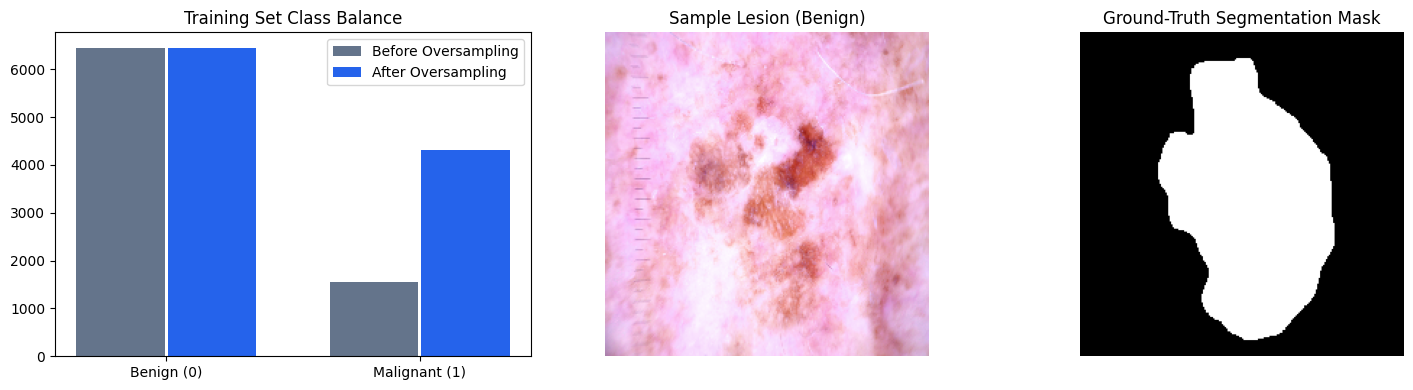

In [2]:
import os
import shutil
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

DRIVE_DATA_DIR = "/content/drive/MyDrive/MagKD_Dataset"
LOCAL_DATA_DIR = "/content/HAM10000_local"

# 2. Copy dataset to fast local Colab SSD
if not os.path.exists(LOCAL_DATA_DIR):
    print("⏳ Copying dataset from Google Drive to fast Colab SSD (takes ~2-3 mins once)...")
    os.makedirs(LOCAL_DATA_DIR, exist_ok=True)

    items_to_copy = [
        "HAM10000_images_part_1",
        "HAM10000_images_part_2",
        "HAM10000_segmentations",
        "HAM10000_metadata.csv"
    ]

    for item in items_to_copy:
        src = os.path.join(DRIVE_DATA_DIR, item)
        dst = os.path.join(LOCAL_DATA_DIR, item)
        if os.path.exists(src):
            if os.path.isdir(src):
                shutil.copytree(src, dst)
            else:
                shutil.copy2(src, dst)
            print(f"  ✔ Copied: {item}")
        else:
            print(f"  ❌ MISSING IN DRIVE: {src} (Please make sure this is uploaded!)")
    print("✅ Fast local dataset ready!")
else:
    print("✅ Local dataset already exists on Colab SSD!")

DATA_DIR = LOCAL_DATA_DIR
IMAGE_DIRS = [
    os.path.join(DATA_DIR, "HAM10000_images_part_1"),
    os.path.join(DATA_DIR, "HAM10000_images_part_2")
]
METADATA_PATH = os.path.join(DATA_DIR, "HAM10000_metadata.csv")
SEG_DIR = os.path.join(DATA_DIR, "HAM10000_segmentations")

# 3. Dataset & Leak-Free Preparation Functions
def load_metadata(metadata_path: str) -> pd.DataFrame:
    df = pd.read_csv(metadata_path)
    # 0 = Benign (Safe), 1 = Malignant (Cancer)
    df['label'] = df['dx'].map({
        'nv': 0, 'bkl': 0, 'df': 0, 'vasc': 0,
        'bcc': 1, 'mel': 1, 'akiec': 1
    })
    return df

class HAM10000Dataset(Dataset):
    def __init__(self, image_paths: list, labels: list, seg_paths: list, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.seg_paths = seg_paths
        self.transform = transform
        self.normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self) -> int:
        return len(self.image_paths)

    def __getitem__(self, idx: int) -> tuple:
        image = np.array(Image.open(self.image_paths[idx]).convert('RGB'))
        seg_mask = np.array(Image.open(self.seg_paths[idx]).convert('L'), dtype=np.uint8)
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        if self.transform:
            augmented = self.transform(image=image, mask=seg_mask)
            image = augmented['image']
            seg_mask = augmented['mask']

        image = torch.from_numpy(image.transpose((2, 0, 1))).float() / 255.0
        image = self.normalize(image)
        seg_mask = (torch.from_numpy(seg_mask).float() / 255.0 > 0.5).float().unsqueeze(0)
        return image, label, seg_mask

def get_train_augmentation() -> A.Compose:
    return A.Compose([
        A.RandomBrightnessContrast(p=0.5, brightness_limit=0.2, contrast_limit=0.2),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.5),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Rotate(limit=25, p=0.5),
        A.Resize(224, 224)
    ], additional_targets={'mask': 'mask'})

def prepare_ham10000_leak_free(metadata_path: str, seg_dir: str):
    metadata = load_metadata(metadata_path)

    img_id_to_path = {}
    for img_dir in IMAGE_DIRS:
        if os.path.exists(img_dir):
            for fname in os.listdir(img_dir):
                if fname.endswith('.jpg'):
                    img_id_to_path[fname.split('.')[0]] = os.path.join(img_dir, fname)

    valid_rows = []
    for _, row in metadata.iterrows():
        img_id = row['image_id']
        seg_path = os.path.join(seg_dir, f"{img_id}_segmentation.png")
        if img_id in img_id_to_path and os.path.exists(seg_path):
            valid_rows.append({
                'image_path': img_id_to_path[img_id],
                'seg_path': seg_path,
                'label': row['label'],
                'lesion_id': row['lesion_id']
            })

    df_valid = pd.DataFrame(valid_rows)

    # Group split by lesion_id so no patient mole is shared between Train, Val, and Test
    sgkf_1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    train_idx, temp_idx = next(sgkf_1.split(df_valid, df_valid['label'], df_valid['lesion_id']))
    df_train = df_valid.iloc[train_idx].reset_index(drop=True)
    df_temp = df_valid.iloc[temp_idx].reset_index(drop=True)

    sgkf_2 = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=42)
    val_idx, test_idx = next(sgkf_2.split(df_temp, df_temp['label'], df_temp['lesion_id']))
    df_val = df_temp.iloc[val_idx].reset_index(drop=True)
    df_test = df_temp.iloc[test_idx].reset_index(drop=True)

    assert len(set(df_train['lesion_id']).intersection(set(df_val['lesion_id']))) == 0
    assert len(set(df_train['lesion_id']).intersection(set(df_test['lesion_id']))) == 0
    print("✅ Verified: Zero patient lesion_id overlap between Train, Val, and Test!")

    # Oversample ONLY training set
    ros = RandomOverSampler(sampling_strategy=0.67, random_state=42)
    train_indices = np.arange(len(df_train)).reshape(-1, 1)
    resampled_idx, _ = ros.fit_resample(train_indices, df_train['label'].values)
    df_train_resampled = df_train.iloc[resampled_idx.flatten()].reset_index(drop=True)

    print(f"Train samples (after oversampling): {len(df_train_resampled)}")
    print(f"Val samples: {len(df_val)} | Test samples: {len(df_test)}")

    val_test_transform = A.Compose([A.Resize(224, 224)], additional_targets={'mask': 'mask'})

    train_ds = HAM10000Dataset(df_train_resampled['image_path'].tolist(), df_train_resampled['label'].tolist(), df_train_resampled['seg_path'].tolist(), transform=get_train_augmentation())
    val_ds = HAM10000Dataset(df_val['image_path'].tolist(), df_val['label'].tolist(), df_val['seg_path'].tolist(), transform=val_test_transform)
    test_ds = HAM10000Dataset(df_test['image_path'].tolist(), df_test['label'].tolist(), df_test['seg_path'].tolist(), transform=val_test_transform)

    # VISUAL CHART 1: Class Distribution & Sample Lesion + Mask
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    before_counts = df_train['label'].value_counts().sort_index()
    after_counts = df_train_resampled['label'].value_counts().sort_index()

    x = np.arange(2)
    axes[0].bar(x - 0.18, before_counts, width=0.35, label='Before Oversampling', color='#64748b')
    axes[0].bar(x + 0.18, after_counts, width=0.35, label='After Oversampling', color='#2563eb')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(['Benign (0)', 'Malignant (1)'])
    axes[0].set_title("Training Set Class Balance")
    axes[0].legend()

    sample_img, sample_lbl, sample_mask = train_ds[0]
    img_vis = np.clip(sample_img.numpy().transpose((1, 2, 0)) * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)
    axes[1].imshow(img_vis)
    axes[1].set_title(f"Sample Lesion ({'Malignant' if sample_lbl.item()==1 else 'Benign'})")
    axes[1].axis('off')

    axes[2].imshow(sample_mask.squeeze(0).numpy(), cmap='gray')
    axes[2].set_title("Ground-Truth Segmentation Mask")
    axes[2].axis('off')
    plt.tight_layout()
    plt.show()

    return train_ds, val_ds, test_ds

train_dataset, val_dataset, test_dataset = prepare_ham10000_leak_free(METADATA_PATH, SEG_DIR)
batch_size = 8
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

# **3. Teacher Model (EfficientNet-B4) with Proper Two-Phase Freezing**
This cell defines the Teacher model and properly freezes the feature extractor during the initial warmup epochs before unfreezing all layers for fine-tuning.

Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b4-6ed6700e.pth" to /root/.cache/torch/hub/checkpoints/efficientnet-b4-6ed6700e.pth


100%|██████████| 74.4M/74.4M [00:00<00:00, 95.0MB/s]


Loaded pretrained weights for efficientnet-b4
--- Phase 1: Teacher Head Warmup (Backbone Frozen) ---
[Warmup] Epoch 1/5 | Train Loss: 0.4383 | Val Loss: 0.2859 | Acc: 0.5369 | Sens: 0.9897 | Spec: 0.4219
[Warmup] Epoch 2/5 | Train Loss: 0.3812 | Val Loss: 0.2722 | Acc: 0.4964 | Sens: 0.9949 | Spec: 0.3698
[Warmup] Epoch 3/5 | Train Loss: 0.3600 | Val Loss: 0.2701 | Acc: 0.4860 | Sens: 0.9949 | Spec: 0.3568
[Warmup] Epoch 4/5 | Train Loss: 0.3609 | Val Loss: 0.2679 | Acc: 0.4808 | Sens: 0.9949 | Spec: 0.3503
[Warmup] Epoch 5/5 | Train Loss: 0.3513 | Val Loss: 0.2630 | Acc: 0.4933 | Sens: 0.9949 | Spec: 0.3659

--- Phase 2: Teacher Full Fine-Tuning (All Layers Unfrozen) ---
[FineTune] Epoch 1/12 | Train Loss: 0.3200 | Val Loss: 0.2287 | Acc: 0.5784 | Sens: 0.9846 | Spec: 0.4753
[FineTune] Epoch 2/12 | Train Loss: 0.2815 | Val Loss: 0.2261 | Acc: 0.6085 | Sens: 0.9897 | Spec: 0.5117
[FineTune] Epoch 3/12 | Train Loss: 0.2596 | Val Loss: 0.2045 | Acc: 0.6677 | Sens: 0.9744 | Spec: 0.5898
[

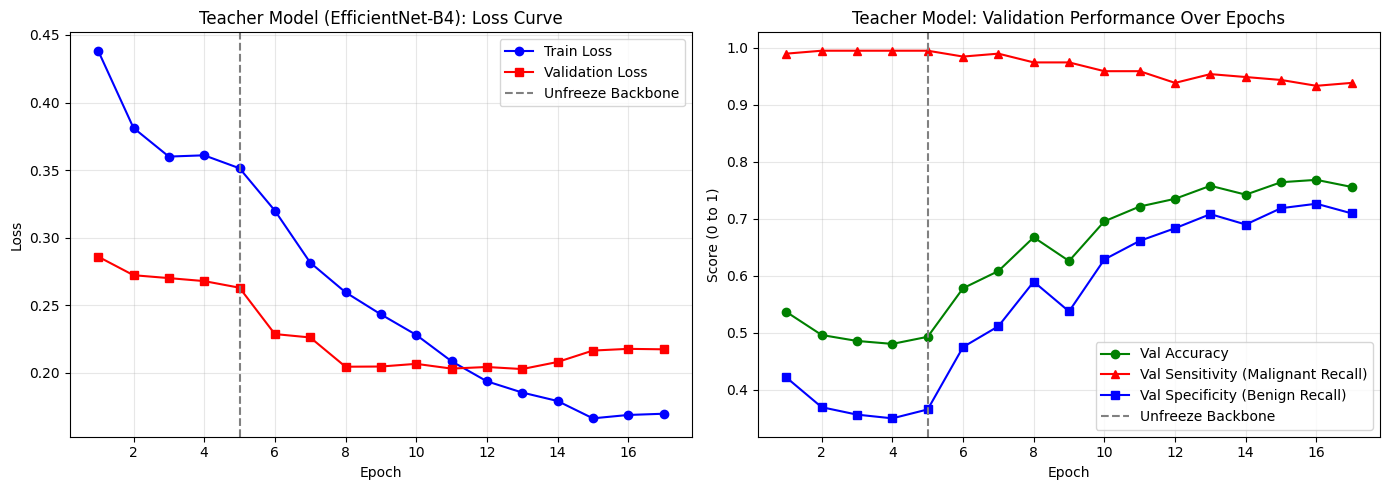

In [3]:
class TeacherModel(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super(TeacherModel, self).__init__()
        self.backbone = EfficientNet.from_pretrained('efficientnet-b4')
        in_features = self.backbone._fc.in_features
        self.backbone._fc = nn.Linear(in_features, 2)

        self.segmentation_head = nn.Sequential(
            nn.Conv2d(self.backbone._conv_head.out_channels, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.ConvTranspose2d(256, 1, kernel_size=4, stride=2, padding=1)
        )

    def forward(self, x):
        features = self.backbone.extract_features(x)             # Shape: [B, 1792, 7, 7]
        class_logits = self.backbone._avg_pooling(features).flatten(1)
        class_logits = self.backbone._dropout(class_logits)
        class_logits = self.backbone._fc(class_logits)           # Shape: [B, 2]
        seg_maps = self.segmentation_head(features)              # Shape: [B, 1, 28, 28]
        return class_logits, seg_maps

def train_teacher_model(model, train_loader, val_loader, epochs_warmup=5, epochs_finetune=12):
    model = model.to(device)
    class_weights = torch.tensor([1.0, 4.0], dtype=torch.float).to(device)
    criterion_class = FocalLoss(alpha=class_weights, gamma=4.0)
    criterion_seg = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())
    accumulation_steps = 4

    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_sens': [], 'val_spec': []}

    def run_phase(optimizer, scheduler, num_epochs, phase_name, save_path):
        best_val_loss = float('inf')
        patience, patience_cnt = 5, 0

        for epoch in range(num_epochs):
            model.train()
            train_loss = 0.0
            optimizer.zero_grad()

            for i, (images, labels, seg_masks) in enumerate(train_loader):
                images, labels, seg_masks = images.to(device), labels.to(device), seg_masks.to(device)

                with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                    class_logits, seg_maps = model(images)
                    c_loss = criterion_class(class_logits, labels)
                    seg_resized = F.interpolate(seg_masks, size=(28, 28), mode='bilinear', align_corners=False)
                    s_loss = criterion_seg(seg_maps, seg_resized)
                    loss = c_loss + 0.3 * s_loss

                scaler.scale(loss / accumulation_steps).backward()
                if (i + 1) % accumulation_steps == 0 or (i + 1) == len(train_loader):
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad()
                train_loss += loss.item()

            scheduler.step()

            # Validation
            model.eval()
            val_loss, all_probs, all_labels = 0.0, [], []
            with torch.no_grad():
                for images, labels, seg_masks in val_loader:
                    images, labels, seg_masks = images.to(device), labels.to(device), seg_masks.to(device)
                    with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                        class_logits, seg_maps = model(images)
                        c_loss = criterion_class(class_logits, labels)
                        seg_resized = F.interpolate(seg_masks, size=(28, 28), mode='bilinear', align_corners=False)
                        s_loss = criterion_seg(seg_maps, seg_resized)
                        loss = c_loss + 0.3 * s_loss
                    val_loss += loss.item()
                    probs = torch.softmax(class_logits, dim=1)[:, 1]
                    all_probs.extend(probs.cpu().numpy())
                    all_labels.extend(labels.cpu().numpy())

            avg_train = train_loss / len(train_loader)
            avg_val = val_loss / len(val_loader)
            preds = (np.array(all_probs) > 0.5).astype(int)
            acc = np.mean(preds == all_labels)
            report = classification_report(all_labels, preds, target_names=['Benign', 'Malignant'], output_dict=True, zero_division=0)
            sens = report['Malignant']['recall']
            spec = report['Benign']['recall']

            history['train_loss'].append(avg_train)
            history['val_loss'].append(avg_val)
            history['val_acc'].append(acc)
            history['val_sens'].append(sens)
            history['val_spec'].append(spec)

            print(f"[{phase_name}] Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train:.4f} | Val Loss: {avg_val:.4f} | Acc: {acc:.4f} | Sens: {sens:.4f} | Spec: {spec:.4f}")

            if avg_val < best_val_loss:
                best_val_loss = avg_val
                torch.save(model.state_dict(), save_path)
                patience_cnt = 0
            else:
                patience_cnt += 1
                if patience_cnt >= patience:
                    print(f"Early stopping {phase_name} at epoch {epoch+1}")
                    break

    # PHASE 1: Freeze Backbone
    print("--- Phase 1: Teacher Head Warmup (Backbone Frozen) ---")
    for param in model.backbone.parameters():
        param.requires_grad = False
    for param in model.backbone._fc.parameters():
        param.requires_grad = True
    for param in model.segmentation_head.parameters():
        param.requires_grad = True

    opt_warmup = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=5e-4, weight_decay=5e-4)
    sched_warmup = CosineAnnealingLR(opt_warmup, T_max=epochs_warmup)
    run_phase(opt_warmup, sched_warmup, epochs_warmup, "Warmup", "teacher_warmup_best.pth")

    # PHASE 2: Unfreeze All Layers
    print("\n--- Phase 2: Teacher Full Fine-Tuning (All Layers Unfrozen) ---")
    model.load_state_dict(torch.load("teacher_warmup_best.pth"))
    for param in model.parameters():
        param.requires_grad = True

    opt_finetune = optim.Adam(model.parameters(), lr=5e-5, weight_decay=5e-4)
    sched_finetune = CosineAnnealingLR(opt_finetune, T_max=epochs_finetune)
    run_phase(opt_finetune, sched_finetune, epochs_finetune, "FineTune", "teacher_model_best.pth")

    model.load_state_dict(torch.load("teacher_model_best.pth"))
    return model, history

teacher_model = TeacherModel(dropout_rate=0.3)
teacher_model, teacher_history = train_teacher_model(teacher_model, train_loader, val_loader, epochs_warmup=5, epochs_finetune=12)

# VISUAL CHART 2: Plot Teacher Training Curves
epochs_range = range(1, len(teacher_history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, teacher_history['train_loss'], 'b-o', label='Train Loss')
axes[0].plot(epochs_range, teacher_history['val_loss'], 'r-s', label='Validation Loss')
axes[0].axvline(x=5, color='gray', linestyle='--', label='Unfreeze Backbone')
axes[0].set_title("Teacher Model (EfficientNet-B4): Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, teacher_history['val_acc'], 'g-o', label='Val Accuracy')
axes[1].plot(epochs_range, teacher_history['val_sens'], 'r-^', label='Val Sensitivity (Malignant Recall)')
axes[1].plot(epochs_range, teacher_history['val_spec'], 'b-s', label='Val Specificity (Benign Recall)')
axes[1].axvline(x=5, color='gray', linestyle='--', label='Unfreeze Backbone')
axes[1].set_title("Teacher Model: Validation Performance Over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score (0 to 1)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# **4. Student Model (MobileNetV3-Large) & MAG-KD Distillation**
This cell builds the lightweight Student model with a 7x7 attention head and trains it using Multi-Attention Guided Knowledge Distillation (MAG-KD).

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 152MB/s]


[MAG-KD Student] Epoch 1/20 | Loss: 0.1169 | Acc: 0.6885 | Sens: 0.9744 | Spec: 0.6159
[MAG-KD Student] Epoch 2/20 | Loss: 0.0904 | Acc: 0.6667 | Sens: 0.9846 | Spec: 0.5859
[MAG-KD Student] Epoch 3/20 | Loss: 0.0803 | Acc: 0.7653 | Sens: 0.9641 | Spec: 0.7148
[MAG-KD Student] Epoch 4/20 | Loss: 0.0750 | Acc: 0.7217 | Sens: 0.9692 | Spec: 0.6589
[MAG-KD Student] Epoch 5/20 | Loss: 0.0680 | Acc: 0.7726 | Sens: 0.9641 | Spec: 0.7240
[MAG-KD Student] Epoch 6/20 | Loss: 0.0614 | Acc: 0.7882 | Sens: 0.9641 | Spec: 0.7435
[MAG-KD Student] Epoch 7/20 | Loss: 0.0561 | Acc: 0.7871 | Sens: 0.9538 | Spec: 0.7448
[MAG-KD Student] Epoch 8/20 | Loss: 0.0517 | Acc: 0.8058 | Sens: 0.9231 | Spec: 0.7760
[MAG-KD Student] Epoch 9/20 | Loss: 0.0477 | Acc: 0.8152 | Sens: 0.9128 | Spec: 0.7904
[MAG-KD Student] Epoch 10/20 | Loss: 0.0438 | Acc: 0.8255 | Sens: 0.9179 | Spec: 0.8021
[MAG-KD Student] Epoch 11/20 | Loss: 0.0411 | Acc: 0.8339 | Sens: 0.9128 | Spec: 0.8138
[MAG-KD Student] Epoch 12/20 | Loss: 0.03

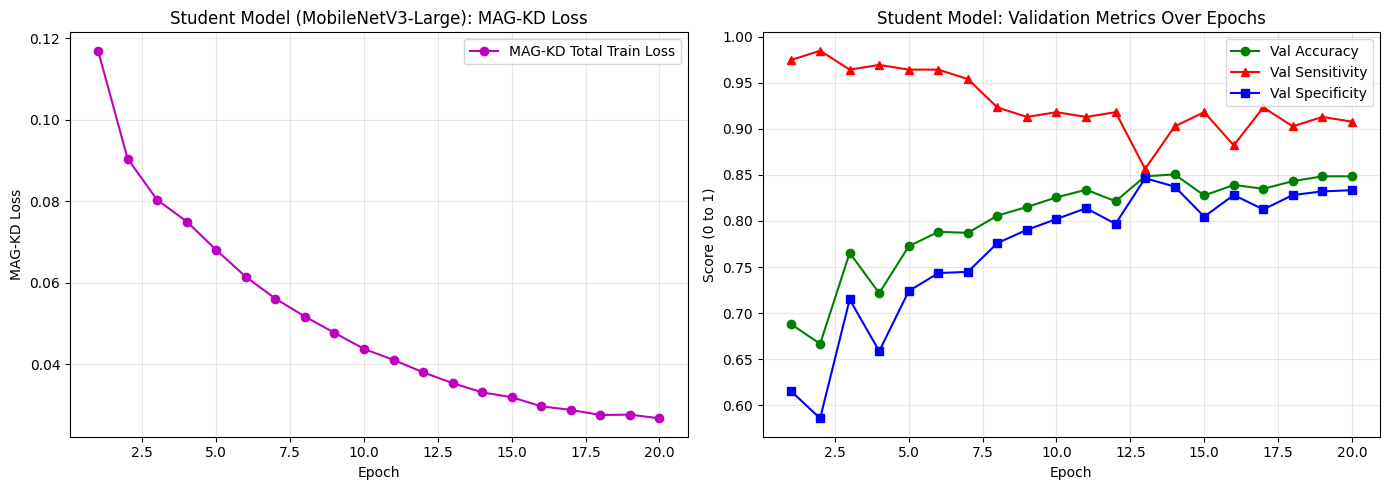

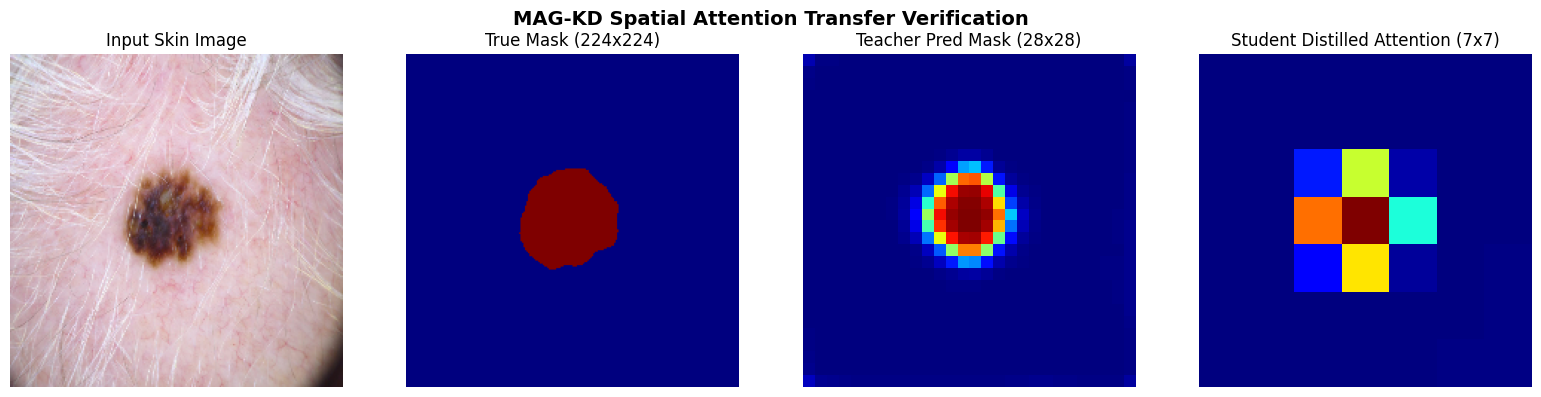

In [4]:
class StudentModel(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super(StudentModel, self).__init__()
        weights = MobileNet_V3_Large_Weights.DEFAULT
        self.backbone = mobilenet_v3_large(weights=weights)

        in_features = self.backbone.classifier[0].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Linear(in_features, 1280),
            nn.Hardswish(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(1280, 2)
        )

        self.attention_head = nn.Sequential(
            nn.Conv2d(960, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 1, kernel_size=1)
        )

    def forward(self, x):
        features = self.backbone.features(x)                     # Shape: [B, 960, 7, 7]
        pooled = self.backbone.avgpool(features).flatten(1)      # Shape: [B, 960]
        class_logits = self.backbone.classifier(pooled)          # Shape: [B, 2]
        att_map = self.attention_head(features)                  # Shape: [B, 1, 7, 7]
        return class_logits, att_map

class MAGKDLoss(nn.Module):
    def __init__(self, class_weights, alpha=0.3, beta=0.4, gamma=0.3, temp=5.0):
        super(MAGKDLoss, self).__init__()
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.temp = temp
        self.focal_loss = FocalLoss(alpha=class_weights, gamma=4.0)
        self.kl_div = nn.KLDivLoss(reduction='batchmean')
        self.mse_loss = nn.MSELoss()

    def forward(self, student_logits, student_att, teacher_logits, teacher_seg, labels):
        loss_cls = self.focal_loss(student_logits, labels)
        student_soft = F.log_softmax(student_logits / self.temp, dim=1)
        teacher_soft = F.softmax(teacher_logits / self.temp, dim=1)
        loss_kd = self.kl_div(student_soft, teacher_soft) * (self.temp ** 2)

        teacher_att_7x7 = F.interpolate(torch.sigmoid(teacher_seg), size=(7, 7), mode='bilinear', align_corners=False)
        student_att_prob = torch.sigmoid(student_att)
        loss_att = self.mse_loss(student_att_prob, teacher_att_7x7)

        return self.alpha * loss_cls + self.beta * loss_kd + self.gamma * loss_att

def train_student_mag_kd(student, teacher, train_loader, val_loader, epochs=20, lr=5e-4):
    student = student.to(device)
    teacher = teacher.to(device)
    teacher.eval()
    for param in teacher.parameters():
        param.requires_grad = False

    class_weights = torch.tensor([1.0, 3.0], dtype=torch.float).to(device)
    mag_kd_criterion = MAGKDLoss(class_weights=class_weights, alpha=0.3, beta=0.4, gamma=0.3, temp=5.0)
    optimizer = optim.AdamW(student.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

    best_score = -float('inf')
    history = {'train_loss': [], 'val_acc': [], 'val_sens': [], 'val_spec': [], 'val_score': []}

    for epoch in range(epochs):
        student.train()
        train_loss = 0.0

        for images, labels, _ in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            with torch.no_grad():
                t_logits, t_seg = teacher(images)

            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                s_logits, s_att = student(images)
                loss = mag_kd_criterion(s_logits, s_att, t_logits, t_seg, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item()

        scheduler.step()

        # Validation
        student.eval()
        all_probs, all_labels = [], []
        with torch.no_grad():
            for images, labels, _ in val_loader:
                images = images.to(device)
                s_logits, _ = student(images)
                probs = torch.softmax(s_logits, dim=1)[:, 1]
                all_probs.extend(probs.cpu().numpy())
                all_labels.extend(labels.numpy())

        preds = (np.array(all_probs) > 0.5).astype(int)
        acc = np.mean(preds == all_labels)
        report = classification_report(all_labels, preds, target_names=['Benign', 'Malignant'], output_dict=True, zero_division=0)
        sens = report['Malignant']['recall']
        spec = report['Benign']['recall']
        score = 0.5 * sens + 0.3 * acc + 0.2 * spec

        avg_loss = train_loss / len(train_loader)
        history['train_loss'].append(avg_loss)
        history['val_acc'].append(acc)
        history['val_sens'].append(sens)
        history['val_spec'].append(spec)
        history['val_score'].append(score)

        print(f"[MAG-KD Student] Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Acc: {acc:.4f} | Sens: {sens:.4f} | Spec: {spec:.4f}")

        if score > best_score:
            best_score = score
            torch.save(student.state_dict(), "student_model_best.pth")

    student.load_state_dict(torch.load("student_model_best.pth"))
    return student, history

student_model = StudentModel(dropout_rate=0.3)
student_model, student_history = train_student_mag_kd(student_model, teacher_model, train_loader, val_loader, epochs=20, lr=5e-4)

# VISUAL CHART 3: Student Training Curves & Attention Alignment Visual Check
s_epochs = range(1, len(student_history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(s_epochs, student_history['train_loss'], 'm-o', label='MAG-KD Total Train Loss')
axes[0].set_title("Student Model (MobileNetV3-Large): MAG-KD Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MAG-KD Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(s_epochs, student_history['val_acc'], 'g-o', label='Val Accuracy')
axes[1].plot(s_epochs, student_history['val_sens'], 'r-^', label='Val Sensitivity')
axes[1].plot(s_epochs, student_history['val_spec'], 'b-s', label='Val Specificity')
axes[1].set_title("Student Model: Validation Metrics Over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score (0 to 1)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Visualize Teacher vs Student Attention Map on a Validation Sample
sample_img, sample_lbl, sample_mask = val_dataset[0]
with torch.no_grad():
    inp = sample_img.unsqueeze(0).to(device)
    _, t_seg = teacher_model(inp)
    _, s_att = student_model(inp)
    t_map = torch.sigmoid(t_seg).squeeze().cpu().numpy()
    s_map = torch.sigmoid(s_att).squeeze().cpu().numpy()

img_vis = np.clip(sample_img.numpy().transpose((1, 2, 0)) * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(img_vis); ax[0].set_title("Input Skin Image"); ax[0].axis('off')
ax[1].imshow(sample_mask.squeeze().numpy(), cmap='jet'); ax[1].set_title("True Mask (224x224)"); ax[1].axis('off')
ax[2].imshow(t_map, cmap='jet'); ax[2].set_title("Teacher Pred Mask (28x28)"); ax[2].axis('off')
ax[3].imshow(s_map, cmap='jet'); ax[3].set_title("Student Distilled Attention (7x7)"); ax[3].axis('off')
plt.suptitle("MAG-KD Spatial Attention Transfer Verification", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# **5. ONNX Export + Full 3-Model Visual Evaluation Dashboard (Teacher vs. Student vs. Quantized ONNX)**

This single cell exports your quantized .onnx model (safely handling Python 3.13), evaluates all 3 models on the unseen Test Set, and plots:

3 Side-by-Side Confusion Matrices (Teacher vs. Student PyTorch vs. Student Quantized ONNX).

Overlayed ROC-AUC Curves for all 3 models.

Grouped Performance Bar Chart (Accuracy, Sensitivity, Specificity, F1-Score) + Model Size (MB) & Inference Speed (ms) Comparison..

## **Export to Web-Safe ONNX & Dynamic Quantization**
During mobile inference, your app only needs the [Benign, Malignant] logits, not the 7x7 training attention map. This cell wraps the student model so it outputs a clean [1, 2] tensor, exports it using ONNX Opset 13, and quantizes it to 8-bit integers

/tmp/ipykernel_544/2541185710.py:38: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✅ Step 1: Exported raw ONNX model (Opset 13) successfully!
✅ Step 2: Quantized ONNX model created successfully!

==================== 3-MODEL BENCHMARK SUMMARY (TEST SET) ====================
                       Model  Accuracy  Sensitivity  Specificity  F1-Score  ROC-AUC  Size (MB)  Latency (ms/img)
1. Teacher (EfficientNet-B4)    0.7407       0.9505       0.6904    0.5863   0.9170   107.2060            6.1077
 2. Student (PyTorch MAG-KD)    0.8134       0.9158       0.7888    0.6549   0.9332    20.4646            1.8858
 3. Student (Quantized ONNX)    0.8134       0.9158       0.7888    0.6549   0.9333    12.5341           11.8870


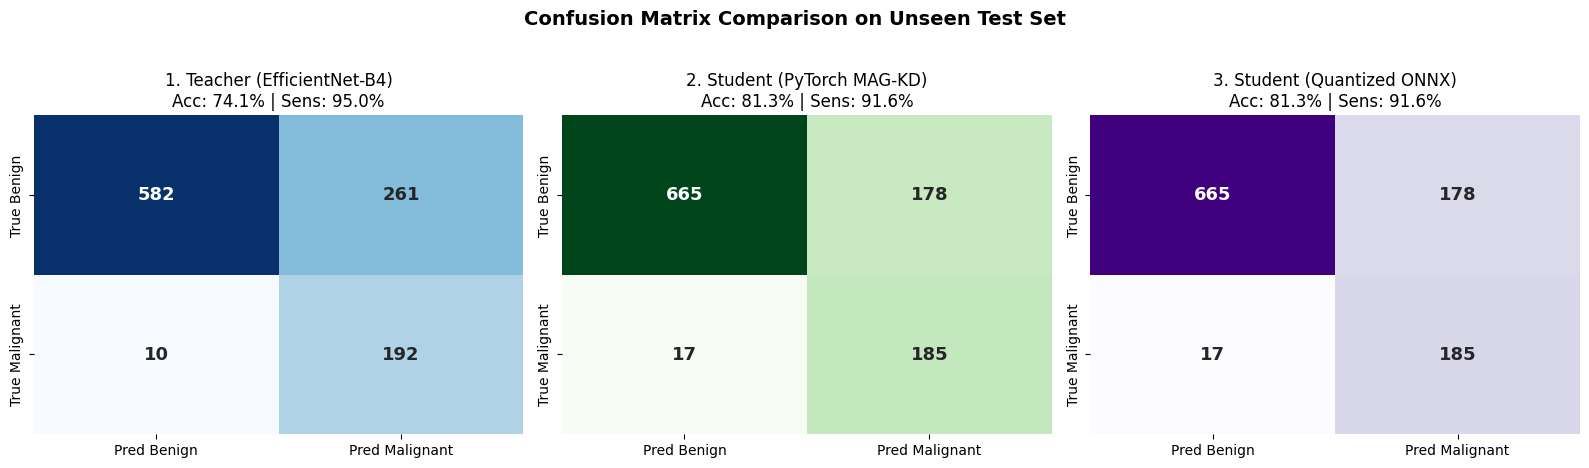

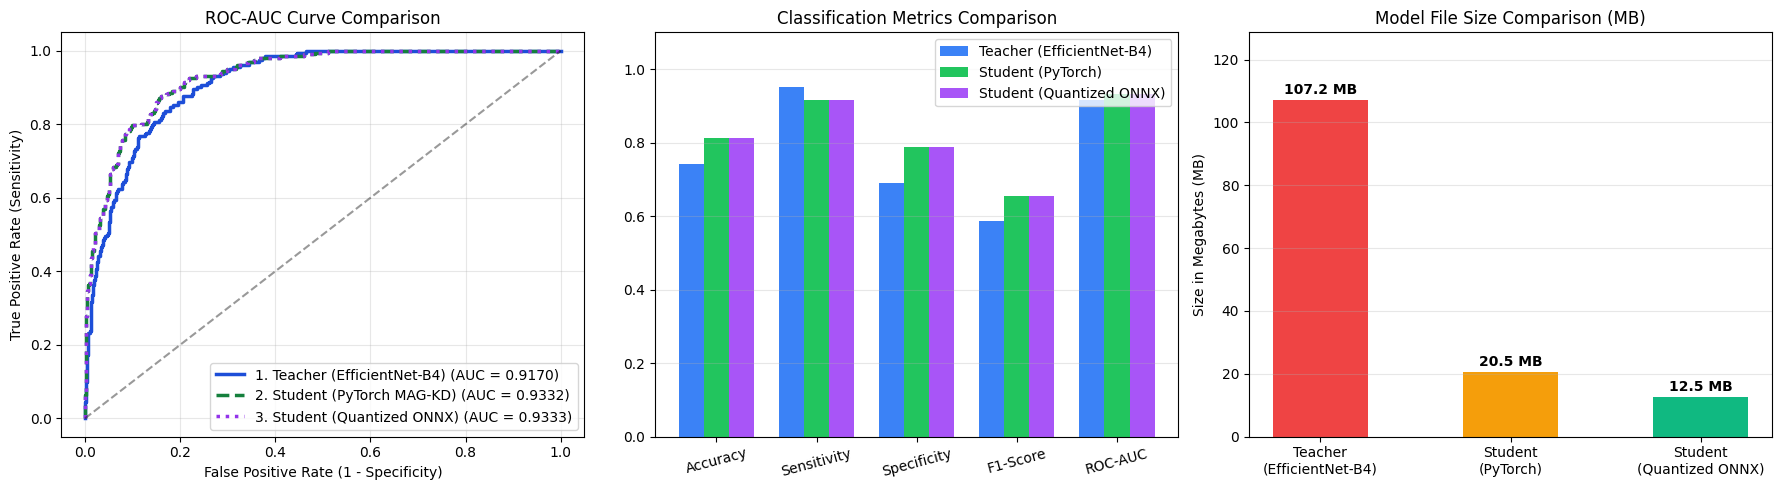

✅ Backed up teacher_model_best.pth to Google Drive!
✅ Backed up student_model_best.pth to Google Drive!
✅ Backed up student_model.onnx to Google Drive!
✅ Backed up student_model_quantized.onnx to Google Drive!


In [7]:
# Install ONNX Runtime in Google Colab
!pip install -q onnx onnxruntime seaborn onnxscript

import os
import time
import copy
import shutil
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import onnx
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix, f1_score

# Wrapper strips out the 7x7 training attention head for fast mobile inference
class StudentDeploymentWrapper(nn.Module):
    def __init__(self, trained_student: StudentModel):
        super(StudentDeploymentWrapper, self).__init__()
        self.student = copy.deepcopy(trained_student)

    def forward(self, x):
        class_logits, _ = self.student(x)
        return class_logits

# 1. Export Student Model to ONNX (Opset 13 + Built-in Constant Folding)
deploy_model = StudentDeploymentWrapper(student_model).cpu().eval()
dummy_input = torch.randn(1, 3, 224, 224, dtype=torch.float32)

onnx_raw_path = "student_model.onnx"
onnx_quant_path = "student_model_quantized.onnx"

torch.onnx.export(
    deploy_model,
    dummy_input,
    onnx_raw_path,
    export_params=True,
    opset_version=13,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}}
)

# 2. Quantize weights to 8-bit unsigned integers (QUInt8)
quantize_dynamic(
    model_input=onnx_raw_path,
    model_output=onnx_quant_path,
    weight_type=QuantType.QUInt8,
    op_types_to_quantize=['MatMul', 'Gemm']
)

# Save Teacher PTH size for comparison
torch.save(teacher_model.state_dict(), "teacher_model_best.pth")
torch.save(student_model.state_dict(), "student_model_best.pth")

teacher_size_mb = os.path.getsize("teacher_model_best.pth") / (1024 * 1024)
student_size_mb = os.path.getsize("student_model_best.pth") / (1024 * 1024)
onnx_quant_size_mb = os.path.getsize(onnx_quant_path) / (1024 * 1024)

# 3. Evaluate ALL 3 Models on the Unseen Test Set (Teacher vs Student PyTorch vs Student Quantized ONNX)
teacher_model.eval()
student_model.eval()
ort_session = ort.InferenceSession(onnx_quant_path)

t_probs, s_probs, o_probs, y_true = [], [], [], []
t_time, s_time, o_time = 0.0, 0.0, 0.0

with torch.no_grad():
    for images, labels, _ in test_loader:
        y_true.extend(labels.numpy())
        img_gpu = images.to(device)
        img_np = images.numpy()

        # Teacher inference
        t0 = time.perf_counter()
        t_logits, _ = teacher_model(img_gpu)
        t_prob = torch.softmax(t_logits, dim=1)[:, 1].cpu().numpy()
        t_time += (time.perf_counter() - t0)
        t_probs.extend(t_prob)

        # Student PyTorch inference
        t0 = time.perf_counter()
        s_logits, _ = student_model(img_gpu)
        s_prob = torch.softmax(s_logits, dim=1)[:, 1].cpu().numpy()
        s_time += (time.perf_counter() - t0)
        s_probs.extend(s_prob)

        # Quantized ONNX Runtime (CPU/Edge) inference
        t0 = time.perf_counter()
        o_logits = ort_session.run(None, {'input': img_np})[0]
        exp_logits = np.exp(o_logits - np.max(o_logits, axis=1, keepdims=True))
        o_prob = (exp_logits / np.sum(exp_logits, axis=1, keepdims=True))[:, 1]
        o_time += (time.perf_counter() - t0)
        o_probs.extend(o_prob)

y_true = np.array(y_true)
t_probs, s_probs, o_probs = np.array(t_probs), np.array(s_probs), np.array(o_probs)

def get_metrics(y_true, probs, total_time, size_mb, name):
    preds = (probs > 0.5).astype(int)
    acc = np.mean(preds == y_true)
    report = classification_report(y_true, preds, target_names=['Benign', 'Malignant'], output_dict=True, zero_division=0)
    sens = report['Malignant']['recall']
    spec = report['Benign']['recall']
    f1 = f1_score(y_true, preds, zero_division=0)
    auc_val = roc_auc_score(y_true, probs)
    ms_per_img = (total_time / len(y_true)) * 1000
    return {
        'Model': name, 'Accuracy': acc, 'Sensitivity': sens, 'Specificity': spec,
        'F1-Score': f1, 'ROC-AUC': auc_val, 'Size (MB)': size_mb, 'Latency (ms/img)': ms_per_img,
        'preds': preds, 'probs': probs
    }

m_teacher = get_metrics(y_true, t_probs, t_time, teacher_size_mb, "1. Teacher (EfficientNet-B4)")
m_student = get_metrics(y_true, s_probs, s_time, student_size_mb, "2. Student (PyTorch MAG-KD)")
m_onnx    = get_metrics(y_true, o_probs, o_time, onnx_quant_size_mb, "3. Student (Quantized ONNX)")

# Print Clean Summary Table
df_summary = pd.DataFrame([m_teacher, m_student, m_onnx]).drop(columns=['preds', 'probs'])
print("\n==================== 3-MODEL BENCHMARK SUMMARY (TEST SET) ====================")
print(df_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# VISUAL CHART 4: 3 Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m, cmap in zip(axes, [m_teacher, m_student, m_onnx], ['Blues', 'Greens', 'Purples']):
    cm = confusion_matrix(y_true, m['preds'])
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax, cbar=False,
                xticklabels=['Pred Benign', 'Pred Malignant'],
                yticklabels=['True Benign', 'True Malignant'], annot_kws={"size": 13, "weight": "bold"})
    ax.set_title(f"{m['Model']}\nAcc: {m['Accuracy']*100:.1f}% | Sens: {m['Sensitivity']*100:.1f}%")
plt.suptitle("Confusion Matrix Comparison on Unseen Test Set", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# VISUAL CHART 5: ROC Curves + Metric Bar Chart + Model Size Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Overlayed ROC-AUC Curves
for m, color, style in zip([m_teacher, m_student, m_onnx], ['#1d4ed8', '#15803d', '#9333ea'], ['-', '--', ':']):
    fpr, tpr, _ = roc_curve(y_true, m['probs'])
    axes[0].plot(fpr, tpr, linestyle=style, linewidth=2.5, color=color, label=f"{m['Model']} (AUC = {m['ROC-AUC']:.4f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_title("ROC-AUC Curve Comparison")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# Subplot 2: Grouped Bar Chart of Classification Metrics
metric_names = ['Accuracy', 'Sensitivity', 'Specificity', 'F1-Score', 'ROC-AUC']
x = np.arange(len(metric_names))
width = 0.25
axes[1].bar(x - width, [m_teacher[k] for k in metric_names], width, label='Teacher (EfficientNet-B4)', color='#3b82f6')
axes[1].bar(x,         [m_student[k] for k in metric_names], width, label='Student (PyTorch)', color='#22c55e')
axes[1].bar(x + width, [m_onnx[k] for k in metric_names],    width, label='Student (Quantized ONNX)', color='#a855f7')
axes[1].set_xticks(x)
axes[1].set_xticklabels(metric_names, rotation=15)
axes[1].set_ylim(0, 1.1)
axes[1].set_title("Classification Metrics Comparison")
axes[1].legend()
axes[1].grid(True, axis='y', alpha=0.3)

# Subplot 3: Model Size Comparison (MB)
models_short = ['Teacher\n(EfficientNet-B4)', 'Student\n(PyTorch)', 'Student\n(Quantized ONNX)']
sizes = [teacher_size_mb, student_size_mb, onnx_quant_size_mb]
bars = axes[2].bar(models_short, sizes, color=['#ef4444', '#f59e0b', '#10b981'], width=0.5)
axes[2].set_title("Model File Size Comparison (MB)")
axes[2].set_ylabel("Size in Megabytes (MB)")
for bar in bars:
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{yval:.1f} MB", ha='center', va='bottom', fontweight='bold')
axes[2].set_ylim(0, max(sizes) * 1.2)
axes[2].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# 4. Backup all models to Google Drive
SAVE_DRIVE_DIR = "/content/drive/MyDrive/MagKD_Dataset/Saved_Models"
os.makedirs(SAVE_DRIVE_DIR, exist_ok=True)

for model_file in ["teacher_model_best.pth", "student_model_best.pth", "student_model.onnx", "student_model_quantized.onnx"]:
    if os.path.exists(model_file):
        shutil.copy2(model_file, os.path.join(SAVE_DRIVE_DIR, model_file))
        print(f"✅ Backed up {model_file} to Google Drive!")